<a href="https://colab.research.google.com/github/Josephbello64/naira-usd-exchange-rate-analysis./blob/main/naira_usd_exchange_rate_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install yfinance -q


In [2]:
import yfinance as yf
import pandas as pd

In [4]:
data = yf.download("NGN=X", start="2019-01-01")
data.head()

/tmp/ipykernel_2528/2248399961.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download("NGN=X", start="2019-01-01")
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,NGN=X,NGN=X,NGN=X,NGN=X,NGN=X
Date,,,,,
2019-01-01,364.000000,364.000000,362.109985,364.000000,0
2019-01-02,362.109985,364.000000,359.160004,362.109985,0
2019-01-03,364.000000,364.000000,361.989990,364.000000,0
2019-01-04,363.500000,364.000000,363.000000,363.500000,0
2019-01-07,364.000000,364.730011,362.760010,364.000000,0


In [5]:
print(data.shape)
data.tail()

(2040, 5)


Price,Close,High,Low,Open,Volume
Ticker,NGN=X,NGN=X,NGN=X,NGN=X,NGN=X
Date,,,,,
2026-10-28,1340.160034,1348.020020,1340.160034,1340.160034,0
2026-10-29,1344.660034,1346.930054,1343.660034,1344.969971,0
2026-10-30,1346.209961,1346.650024,1345.589966,1346.640015,0
2026-11-02,1345.969971,1344.479980,1340.430054,1344.260010,0
2026-11-03,1336.630005,1336.630005,1336.630005,1336.630005,0


In [6]:
df = data["Close"].reset_index()
df.columns = ["date", "usd_to_ngn"]
df.head()

,date,usd_to_ngn
0,2019-01-01,364.000000
1,2019-01-02,362.109985
2,2019-01-03,364.000000
3,2019-01-04,363.500000
4,2019-01-07,364.000000


In [7]:
print(df.info())
print("Missing values:")
print(df.isna().sum())
print("Duplicate dates:", df.duplicated(subset="date").sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2040 entries, 0 to 2039
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        2040 non-null   datetime64[ns]
 1   usd_to_ngn  2040 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 32.0 KB
None
Missing values:
date          0
usd_to_ngn    0
dtype: int64
Duplicate dates: 0


In [8]:
highest = df.loc[df["usd_to_ngn"].idxmax()]
lowest = df.loc[df["usd_to_ngn"].idxmin()]

print("Highest:", highest["usd_to_ngn"], "on", highest["date"].date())
print("Lowest:", lowest["usd_to_ngn"], "on", lowest["date"].date())


Highest: 1696.199951171875 on 2024-11-25
Lowest: 305.9100036621094 on 2019-06-11


In [10]:
df["year"] = df["date"].dt.year
yearly = df.groupby("year")["usd_to_ngn"].mean().round(0)
print(yearly)

year
2019     358.0
2020     377.0
2021     399.0
2022     423.0
2023     635.0
2024    1478.0
2025    1520.0
2026    1363.0
Name: usd_to_ngn, dtype: float64


In [11]:
df["daily_change_pct"] = df["usd_to_ngn"].pct_change() * 100
biggest = df.loc[df["daily_change_pct"].abs().idxmax()]

print("Biggest one-day move:", round(biggest["daily_change_pct"], 1), "% on", biggest["date"].date())

Biggest one-day move: 33.3 % on 2024-02-01


In [12]:
# Show 3 rows before and after the lowest day
i = df["usd_to_ngn"].idxmin()
print(df.loc[i-3:i+3, ["date", "usd_to_ngn"]])

# Show 3 rows before and after the biggest move
j = df["daily_change_pct"].abs().idxmax()
print(df.loc[j-3:j+3, ["date", "usd_to_ngn", "daily_change_pct"]])

          date  usd_to_ngn
111 2019-06-06  305.950012
112 2019-06-07  306.200012
113 2019-06-10  306.200012
114 2019-06-11  305.910004
115 2019-06-12  356.000000
116 2019-06-13  356.000000
117 2019-06-14  356.000000
           date   usd_to_ngn  daily_change_pct
1323 2024-01-29   898.700012          1.204956
1324 2024-01-30   893.000000         -0.634251
1325 2024-01-31   896.000000          0.335946
1326 2024-02-01  1194.000000         33.258929
1327 2024-02-02  1192.000000         -0.167504
1328 2024-02-05  1192.000000          0.000000
1329 2024-02-06  1400.099976         17.458052


In [13]:
# Keep only data from 12 June 2019 onwards
df = df[df["date"] >= "2019-06-12"].reset_index(drop=True)

# Average rate per year, and % change from the previous year
df["year"] = df["date"].dt.year
yearly = df.groupby("year")["usd_to_ngn"].mean().round(0)
print(yearly)
print((yearly.pct_change() * 100).round(1))

# Highest and lowest again
highest = df.loc[df["usd_to_ngn"].idxmax()]
lowest = df.loc[df["usd_to_ngn"].idxmin()]
print("Highest:", round(highest["usd_to_ngn"]), "on", highest["date"].date())
print("Lowest:", round(lowest["usd_to_ngn"]), "on", lowest["date"].date())

year
2019     359.0
2020     377.0
2021     399.0
2022     423.0
2023     635.0
2024    1478.0
2025    1520.0
2026    1363.0
Name: usd_to_ngn, dtype: float64
year
2019      NaN
2020      5.0
2021      5.8
2022      6.0
2023     50.1
2024    132.8
2025      2.8
2026    -10.3
Name: usd_to_ngn, dtype: float64
Highest: 1696 on 2024-11-25
Lowest: 355 on 2019-06-20


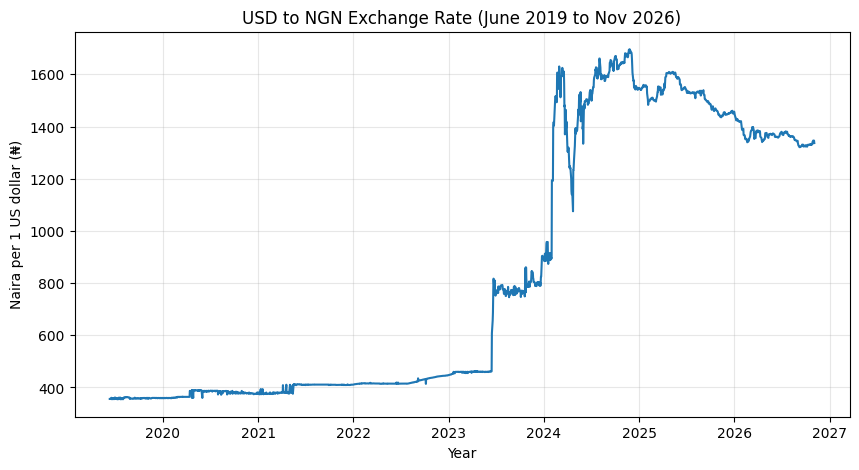

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(df["date"], df["usd_to_ngn"], color="#1f77b4", linewidth=1.5)
plt.title("USD to NGN Exchange Rate (June 2019 to Nov 2026)")
plt.xlabel("Year")
plt.ylabel("Naira per 1 US dollar (₦)")
plt.grid(alpha=0.3)
plt.savefig("usd_ngn_trend.png", dpi=150, bbox_inches="tight")
plt.show()

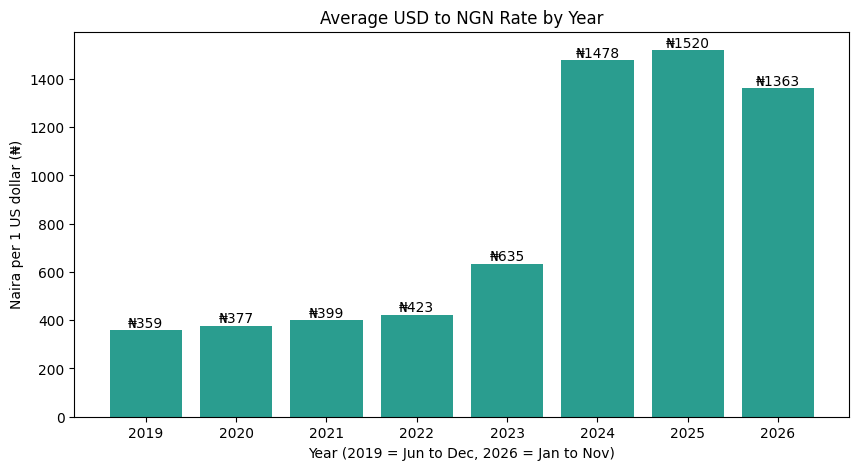

In [18]:
plt.figure(figsize=(10, 5))
bars = plt.bar(yearly.index.astype(str), yearly.values, color="#2a9d8f")
plt.bar_label(bars, fmt="₦%.0f")
plt.title("Average USD to NGN Rate by Year")
plt.xlabel("Year (2019 = Jun to Dec, 2026 = Jan to Nov)")
plt.ylabel("Naira per 1 US dollar (₦)")
plt.savefig("usd_ngn_yearly.png", dpi=150, bbox_inches="tight")
plt.show()

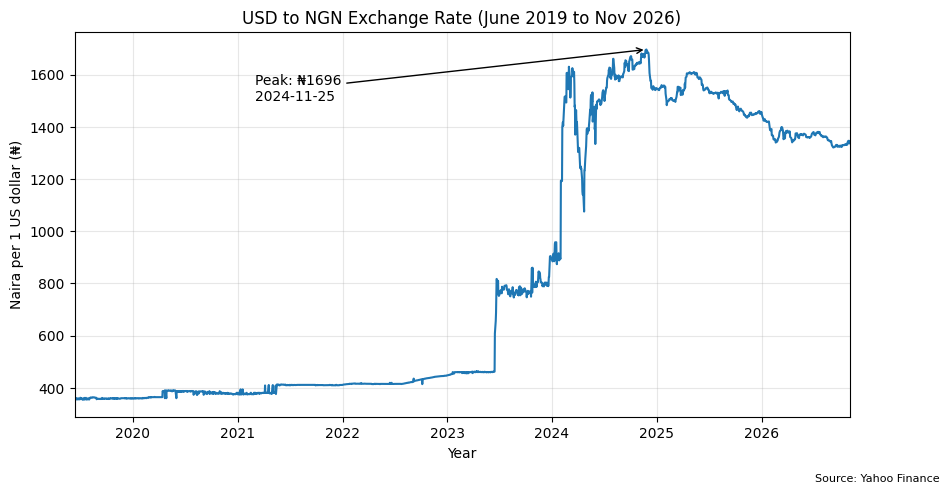

In [16]:
plt.figure(figsize=(10, 5))
plt.plot(df["date"], df["usd_to_ngn"], color="#1f77b4", linewidth=1.5)

# Mark the peak with an arrow and label
peak = df.loc[df["usd_to_ngn"].idxmax()]
plt.annotate(f"Peak: ₦{peak['usd_to_ngn']:.0f}\n{peak['date'].date()}",
             xy=(peak["date"], peak["usd_to_ngn"]),
             xytext=(pd.Timestamp("2021-03-01"), 1500),
             arrowprops=dict(arrowstyle="->"))

plt.xlim(df["date"].min(), df["date"].max())
plt.title("USD to NGN Exchange Rate (June 2019 to Nov 2026)")
plt.xlabel("Year")
plt.ylabel("Naira per 1 US dollar (₦)")
plt.grid(alpha=0.3)
plt.figtext(0.99, -0.02, "Source: Yahoo Finance", ha="right", fontsize=8)
plt.savefig("usd_ngn_trend.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
sample = df[(df["date"] >= "2025-11-13") & (df["date"] <= "2025-12-10")]
print(sample[["date", "usd_to_ngn"]].to_string(index=False))

      date  usd_to_ngn
2025-11-13 1441.829956
2025-11-14 1440.829956
2025-11-17 1440.280029
2025-11-18 1444.550049
2025-11-19 1444.000000
2025-11-20 1450.640015
2025-11-21 1454.060059
2025-11-24 1451.920044
2025-11-25 1454.250000
2025-11-26 1448.810059
2025-11-27 1446.520020
2025-11-28 1444.520020
2025-12-01 1446.670044
2025-12-02 1446.449951
2025-12-03 1446.739990
2025-12-04 1447.699951
2025-12-05 1446.859985
2025-12-08 1449.579956
2025-12-09 1450.619995
2025-12-10 1450.800049
